# 15 — X-IIoTID Core19 | Model Diversity & Exploratory Ensemble Validation

**J26-CS-336 · Network Flow V2 · Validation-only experiment**

**Question:** Does combining **LightGBM**, **Decision Tree**, and **Random Forest** detect attacks that another model misses, and does that improve the detection/resource trade-off?

### Simple terms
- **Model diversity:** Two models make *different mistakes*. **IIoT example:** LightGBM misses a suspicious CoAP flow that Decision Tree detects. **Everyday example:** Two doctors notice different warning signs.
- **Rescue:** Model B correctly recognizes an attack that Model A missed. A rescue is a *potential* benefit, **not proof** an actual ensemble can achieve it.
- **Majority vote:** Three models vote Normal/Attack; at least two must vote Attack.
- **Soft vote:** Average the three attack probabilities; predict Attack when the average is at least 0.5. Probabilities may be poorly calibrated—this is an exploratory baseline.

### Safeguards
- **No retraining.** Load your three **saved, full-trained** `.joblib` pipelines.
- **No test data.** Read **only** the frozen 123,125-record validation partition.
- Confirm each saved pipeline exactly reproduces the confusion matrix reported by the original model notebook. Stop on mismatch: an old pilot model can otherwise invalidate this analysis.
- Evaluate *exploratory* ensembles on validation, **not** the held-out test set.
- These are classification experiments, **not** Raspberry Pi or end-to-end APT campaign benchmarks.

**Execution:** Save as `network_flow_v2/notebooks/x_iiotid/15_x_iiotid_error_diversity_and_ensemble_screening.ipynb` and run the cells top to bottom using your existing `.venv` Python kernel.

## A. Setup and verify project paths

In [1]:
from pathlib import Path
import sys, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score

ROOT = Path(r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2")
assert ROOT.is_dir(), f"Project folder not found: {ROOT}"
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from x_iiotid_model_runner import CORE19, clean_features, read_partition

AUDIT = ROOT / "reports" / "audits"
FIGS = ROOT / "reports" / "figures"
MODELS_DIR = ROOT / "models" / "x_iiotid"
FIGS.mkdir(parents=True, exist_ok=True)
AUDIT.mkdir(parents=True, exist_ok=True)

MODELS = ["decision_tree", "random_forest", "lightgbm"]
LABELS = {"decision_tree": "Decision Tree", "random_forest": "Random Forest", "lightgbm": "LightGBM"}
EXPECTED_TRAIN_ROWS = 574_585
EXPECTED_VALIDATION_ROWS = 123_125

for name in MODELS:
    p = MODELS_DIR / f"{name}_core19_v1.joblib"
    report = AUDIT / f"x_iiotid_{name}_validation_v1.csv"
    if not p.is_file() or not report.is_file():
        raise FileNotFoundError(f"Model/report missing for {name}: {p} / {report}")

print("Workspace:", ROOT)
print("Saved models found:", ", ".join(MODELS))
print("TEST dataset will NOT be opened.")

Workspace: D:\J26-CS-336-Network-Flow-V2\network_flow_v2
Saved models found: decision_tree, random_forest, lightgbm
TEST dataset will NOT be opened.


## B. Load validation records and verify same frozen split

**`class3`:** actual binary Normal / Attack label. **`class2`:** broader attack category for later error analysis. **`csv_row_index_0based`:** original row identifier to preserve alignment across model predictions.

In [2]:
validation = read_partition(ROOT, "validation")
assert len(validation) == EXPECTED_VALIDATION_ROWS, len(validation)
assert validation["csv_row_index_0based"].is_unique
assert validation["class3"].isin(["Normal", "Attack"]).all()
y = validation["class3"].map({"Normal": 0, "Attack": 1}).to_numpy(dtype=np.uint8)
X = clean_features(validation)
assert list(X.columns) == list(CORE19)

reports = {}
for name in MODELS:
    report = pd.read_csv(AUDIT / f"x_iiotid_{name}_validation_v1.csv").iloc[0]
    assert int(report["train_rows_used"]) == EXPECTED_TRAIN_ROWS, f"{name}: not full-trained report"
    assert int(report["validation_rows"]) == len(y), f"{name}: validation count differs"
    assert str(report["features"]) == "Core19", f"{name}: different features"
    test_flag = str(report["test_evaluated"]).strip().lower()
    assert test_flag in ("false", "0"), f"{name}: test evaluation flag isn't false"
    reports[name] = report
manifest_hashes = {str(reports[name]["frozen_manifest_sha256"]) for name in MODELS}
assert len(manifest_hashes) == 1, "Reports refer to DIFFERENT frozen split manifests!"

print(f"Validation: {len(y):,} rows | Normal: {(y==0).sum():,} | Attack: {(y==1).sum():,}")
print("Training rows recorded in all three model reports:", EXPECTED_TRAIN_ROWS)
print("All reports share frozen-manifest SHA256:", next(iter(manifest_hashes)))
print("X feature columns:", len(X.columns), "(Core19)")

Validation: 123,125 rows | Normal: 63,213 | Attack: 59,912
Training rows recorded in all three model reports: 574585
All reports share frozen-manifest SHA256: 8704e269d96abfe61b61a4608ab4e2f0608952555d6b34730da92ebac31fe2c0
X feature columns: 19 (Core19)


## C. Load each saved pipeline and reproduce its exact validation predictions

We apply the **same cleaned validation inputs** to each saved *preprocessing + classifier* pipeline. The cell **fails on any disagreement** with the saved TN/FP/FN/TP numbers, rather than silently analyzing a mismatched or old model.

*Safety:* `joblib.load` should only be used with your own trusted model files.

In [3]:
predictions = {}
attack_probabilities = {}
verification_rows = []

for name in MODELS:
    path = MODELS_DIR / f"{name}_core19_v1.joblib"
    print(f"Scoring saved {LABELS[name]} pipeline ...", flush=True)
    model = joblib.load(path)  # Only load your own trusted local model artifacts.
    if not hasattr(model, "named_steps") or not {"preprocessing", "classifier"}.issubset(model.named_steps):
        raise TypeError(f"{name}: expected saved preprocessing + classifier pipeline")
    if not np.array_equal(np.asarray(model.classes_), [0, 1]):
        raise ValueError(f"{name}: unexpected class order {model.classes_!r}")

    pred = np.asarray(model.predict(X), dtype=np.uint8)
    if pred.shape != y.shape or not np.isin(pred, [0, 1]).all():
        raise ValueError(f"{name}: invalid prediction shape or labels")
    tn, fp, fn, tp = map(int, confusion_matrix(y, pred, labels=[0, 1]).ravel())
    r = reports[name]
    expected = tuple(int(r[k]) for k in ("tn", "fp", "fn", "tp"))
    got = (tn, fp, fn, tp)
    if got != expected:
        raise AssertionError(
            f"{name}: saved model does not match full-training validation report! "
            f"got TN/FP/FN/TP={got}, expected={expected}. "
            "Stop; check model artifact dates/versions. Do not retrain automatically."
        )

    predictions[name] = pred
    # Only use soft voting if every pipeline can return Attack probabilities.
    if hasattr(model, "predict_proba"):
        proba = np.asarray(model.predict_proba(X), dtype=np.float64)
        if proba.shape != (len(y), 2) or not np.isfinite(proba).all():
            raise ValueError(f"{name}: invalid predict_proba output")
        attack_probabilities[name] = proba[:, 1].copy()

    verification_rows.append({"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp, "report_matched": True})
    del model
    gc.collect()

verified = pd.DataFrame(verification_rows)
display(verified)
print("PASS: every saved model reproduces its full-training validation confusion matrix.")

Scoring saved Decision Tree pipeline ...
Scoring saved Random Forest pipeline ...
Scoring saved LightGBM pipeline ...


,model,TN,FP,FN,TP,report_matched
0,decision_tree,62579,634,1245,58667,True
1,random_forest,62302,911,593,59319,True
2,lightgbm,62491,722,574,59338,True


PASS: every saved model reproduces its full-training validation confusion matrix.


## D. Measure diversity: how many missed attacks does another model rescue?

- **Both miss** = difficult attacks missed by the pair.
- **A misses, B catches** = possible complementary value from B when paired with A.
- **A catches, B misses** = possible complementary value from A when paired with B.
- A pair having *different errors* supports testing an ensemble, but **does not prove** that a voting rule will perform better.

In [4]:
attack = (y == 1)
normal = (y == 0)
miss_rows = []
for a in MODELS:
    for b in MODELS:
        if a == b:
            continue
        a_misses = attack & (predictions[a] == 0)
        b_catches = attack & (predictions[b] == 1)
        b_misses = attack & (predictions[b] == 0)
        miss_rows.append({
            "model_a_missed": a,
            "model_b_rescues": b,
            "a_missed_attacks_total": int(a_misses.sum()),
            "rescued_by_b": int((a_misses & b_catches).sum()),
            "both_miss": int((a_misses & b_misses).sum()),
            "rescue_percent_of_a_misses": 100 * (a_misses & b_catches).sum() / max(a_misses.sum(), 1),
        })
rescue_df = pd.DataFrame(miss_rows)
display(rescue_df.sort_values(["model_a_missed", "model_b_rescues"]).round(2))
rescue_path = AUDIT / "x_iiotid_core19_model_error_rescues_v1.csv"
rescue_df.to_csv(rescue_path, index=False)
print("Saved:", rescue_path)

,model_a_missed,model_b_rescues,a_missed_attacks_total,rescued_by_b,both_miss,rescue_percent_of_a_misses
1,decision_tree,lightgbm,1245,729,516,58.55
0,decision_tree,random_forest,1245,765,480,61.45
4,lightgbm,decision_tree,574,58,516,10.10
5,lightgbm,random_forest,574,88,486,15.33
2,random_forest,decision_tree,593,113,480,19.06
3,random_forest,lightgbm,593,107,486,18.04


Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_core19_model_error_rescues_v1.csv


## E. Graph 1 — Actual missed attacks per model (lower is better)

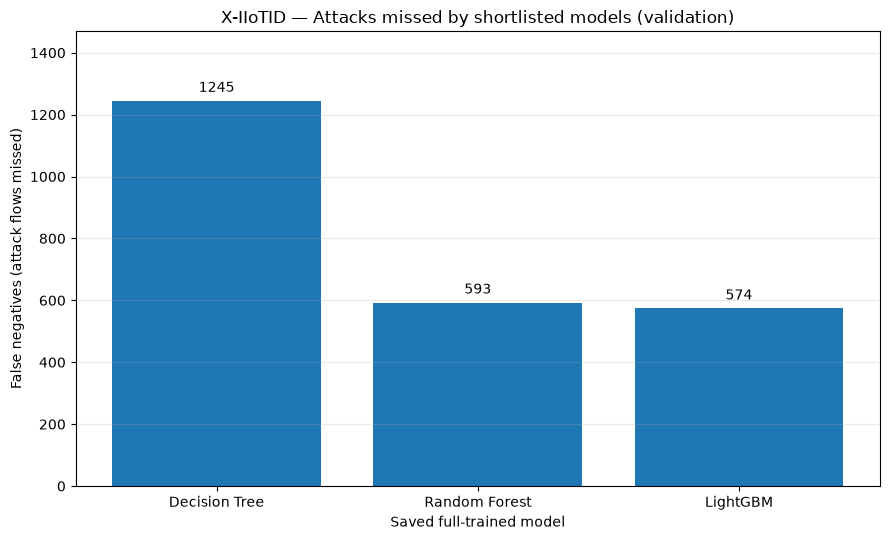

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_core19_missed_attacks_three_models_v1.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
misses = [int((attack & (predictions[n] == 0)).sum()) for n in MODELS]
bars = ax.bar([LABELS[n] for n in MODELS], misses)
ax.bar_label(bars, padding=4)
ax.set_title("X-IIoTID — Attacks missed by shortlisted models (validation)")
ax.set_xlabel("Saved full-trained model")
ax.set_ylabel("False negatives (attack flows missed)")
ax.set_ylim(0, max(misses) * 1.18)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
p = FIGS / "x_iiotid_core19_missed_attacks_three_models_v1.png"
fig.savefig(p, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", p)

## F. Graph 2 — Rescue heatmap (row model misses, column model catches)

**How to read:** A large number at **LightGBM row → Decision Tree column** means Decision Tree catches many attacks that LightGBM missed. Values on the diagonal are intentionally blank.

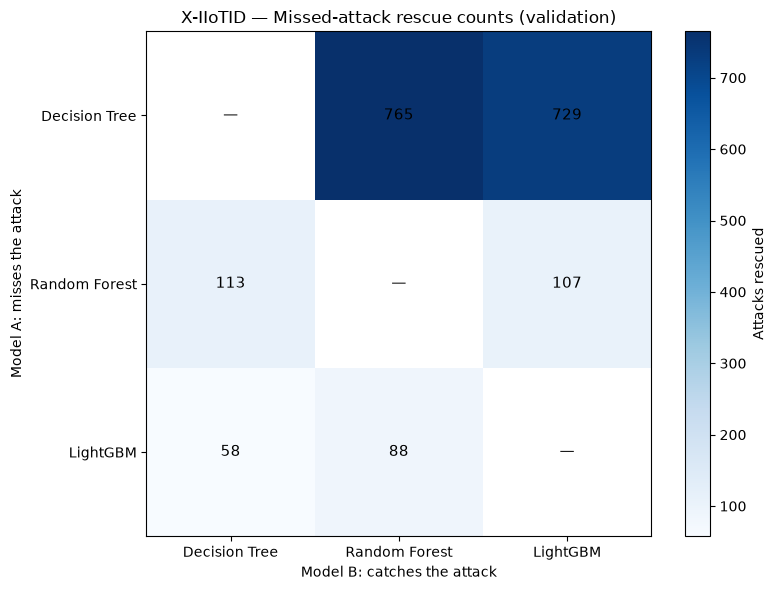

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_core19_attack_rescue_heatmap_v1.png


In [6]:
matrix = np.full((len(MODELS), len(MODELS)), np.nan)
for i, a in enumerate(MODELS):
    for j, b in enumerate(MODELS):
        if a != b:
            matrix[i, j] = int((attack & (predictions[a] == 0) & (predictions[b] == 1)).sum())
fig, ax = plt.subplots(figsize=(8, 6))
heat = ax.imshow(np.ma.masked_invalid(matrix), cmap="Blues")
ax.set_xticks(range(len(MODELS)), [LABELS[m] for m in MODELS])
ax.set_yticks(range(len(MODELS)), [LABELS[m] for m in MODELS])
ax.set_xlabel("Model B: catches the attack")
ax.set_ylabel("Model A: misses the attack")
ax.set_title("X-IIoTID — Missed-attack rescue counts (validation)")
for i in range(len(MODELS)):
    for j in range(len(MODELS)):
        ax.text(j, i, "—" if i == j else f"{int(matrix[i,j]):,}",
                ha="center", va="center", color="black", fontsize=11)
fig.colorbar(heat, ax=ax, label="Attacks rescued")
plt.tight_layout()
p = FIGS / "x_iiotid_core19_attack_rescue_heatmap_v1.png"
fig.savefig(p, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", p)

## G. Exploratory ensembles — no new training

We compare **individual models**, **majority vote among three**, and **soft voting** on the *same validation rows*.

- **Majority vote (three):** predicts Attack when at least 2 models vote Attack.
- **Soft voting:** predicts Attack when the mean of model Attack probabilities is >= 0.5.
- **Two-model soft votes:** average the two probabilities (no arbitrary tie-breaking).

**Warning:** A threshold of 0.5 is an initial choice. These raw model probabilities are not necessarily calibrated. We will evaluate alternative thresholds/calibration using proper validation procedures later and finally score the held-out test once after the design is locked.

In [7]:
candidate_predictions = {LABELS[m]: predictions[m] for m in MODELS}

# Three-model majority vote; no ties possible.
raw_votes = np.column_stack([predictions[m] for m in MODELS])
candidate_predictions["Majority vote (3)"] = (raw_votes.sum(axis=1) >= 2).astype(np.uint8)

if len(attack_probabilities) == len(MODELS):
    for a, b in [("lightgbm", "decision_tree"), ("lightgbm", "random_forest"), ("decision_tree", "random_forest")]:
        mean_proba = (attack_probabilities[a] + attack_probabilities[b]) / 2
        candidate_predictions[f"Soft vote: {LABELS[a]} + {LABELS[b]}"] = (mean_proba >= 0.5).astype(np.uint8)
    mean_all = np.mean(np.column_stack([attack_probabilities[m] for m in MODELS]), axis=1)
    candidate_predictions["Soft vote (3)"] = (mean_all >= 0.5).astype(np.uint8)
else:
    print("Some pipelines lack predict_proba; skipping soft voting.")

def metrics_for(name, pred):
    tn, fp, fn, tp = map(int, confusion_matrix(y, pred, labels=[0, 1]).ravel())
    return {
        "candidate": name,
        "precision_attack": precision_score(y, pred, zero_division=0),
        "recall_attack": recall_score(y, pred, zero_division=0),
        "f1_attack": f1_score(y, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "false_positive_rate": fp / max(tn + fp, 1),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }

comparison = pd.DataFrame([metrics_for(name, pred) for name, pred in candidate_predictions.items()])
comparison = comparison.sort_values("f1_attack", ascending=False).reset_index(drop=True)
display(comparison.round(4))
comparison_path = AUDIT / "x_iiotid_core19_exploratory_ensemble_validation_v1.csv"
comparison.to_csv(comparison_path, index=False)
print("Saved:", comparison_path)
print("NOTE: This ranks VALIDATION classification only, not edge-resource efficiency.")

,candidate,precision_attack,recall_attack,f1_attack,balanced_accuracy,false_positive_rate,tn,fp,fn,tp
0,Majority vote (3),0.9888,0.9905,0.9896,0.9899,0.0107,62538,675,572,59340
1,Soft vote: LightGBM + Decision Tree,0.9880,0.9909,0.9894,0.9897,0.0114,62491,722,547,59365
2,Soft vote (3),0.9881,0.9906,0.9894,0.9897,0.0113,62501,712,562,59350
3,Soft vote: LightGBM + Random Forest,0.9883,0.9903,0.9893,0.9896,0.0111,62513,700,580,59332
4,LightGBM,0.9880,0.9904,0.9892,0.9895,0.0114,62491,722,574,59338
5,Random Forest,0.9849,0.9901,0.9875,0.9878,0.0144,62302,911,593,59319
6,Soft vote: Decision Tree + Random Forest,0.9843,0.9848,0.9845,0.9849,0.0149,62270,943,913,58999
7,Decision Tree,0.9893,0.9792,0.9842,0.9846,0.0100,62579,634,1245,58667


Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_core19_exploratory_ensemble_validation_v1.csv
NOTE: This ranks VALIDATION classification only, not edge-resource efficiency.


## H. Graph 3 — Compare ensemble F1-scores (validation only)

Show this after the rescue heatmap: an ensemble may be **worse** than the strongest individual model. This is why we measure rather than assume.

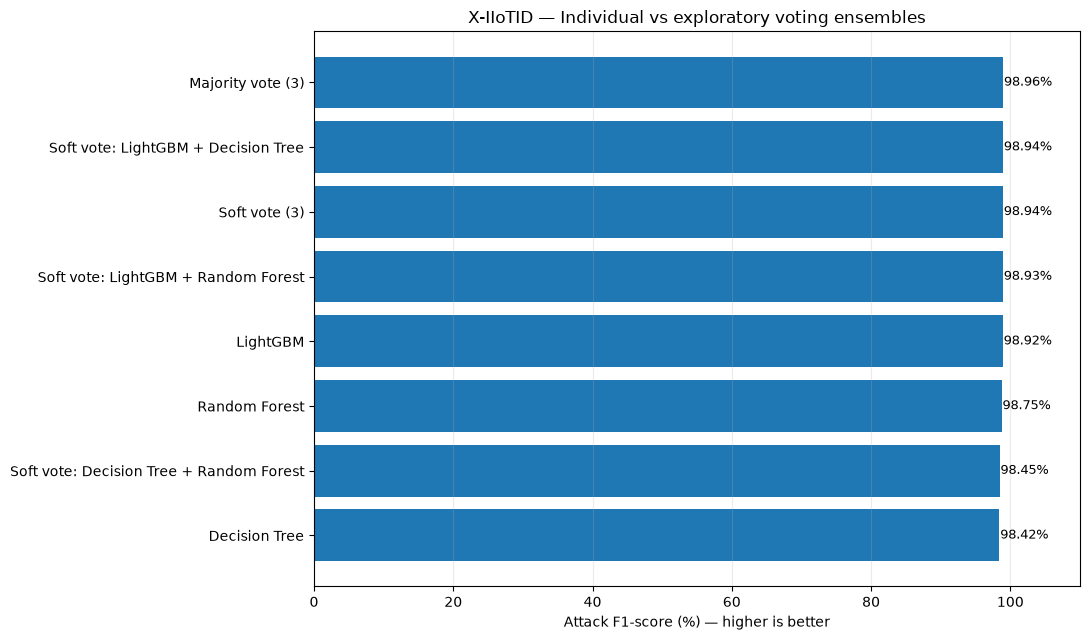

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_core19_exploratory_ensemble_f1_v1.png


In [8]:
ordered = comparison.sort_values("f1_attack", ascending=True)
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(ordered["candidate"], ordered["f1_attack"] * 100)
for rect, f1 in zip(bars, ordered["f1_attack"]):
    ax.text(rect.get_width() + 0.12, rect.get_y() + rect.get_height()/2, f"{f1*100:.2f}%", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("Attack F1-score (%) — higher is better")
ax.set_title("X-IIoTID — Individual vs exploratory voting ensembles")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
p = FIGS / "x_iiotid_core19_exploratory_ensemble_f1_v1.png"
fig.savefig(p, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", p)

## I. Check error distribution by attack category (`class2`)

This shows whether good overall scores hide poor recall on certain attacks. **Rare categories can have unstable percentages.** It is not an APT campaign or MITRE technique classification.

In [9]:
cats = validation["class2"].astype(str).str.strip().replace("", "__MISSING__")
attack_counts = cats[attack].value_counts()
category_rows = []
for category, count in attack_counts.items():
    mask = attack & (cats.to_numpy() == category)
    entry = {"class2": category, "attack_rows": int(count)}
    for name in MODELS:
        entry[f"fn_{name}"] = int((mask & (predictions[name] == 0)).sum())
        entry[f"recall_{name}"] = 1 - entry[f"fn_{name}"] / count
    entry["fn_majority_vote_3"] = int((mask & (candidate_predictions["Majority vote (3)"] == 0)).sum())
    entry["recall_majority_vote_3"] = 1 - entry["fn_majority_vote_3"] / count
    category_rows.append(entry)
category_df = pd.DataFrame(category_rows).sort_values("attack_rows", ascending=False)
display(category_df.head(15).round(3))
category_path = AUDIT / "x_iiotid_core19_attack_category_error_comparison_v1.csv"
category_df.to_csv(category_path, index=False)
print("Saved:", category_path)

,class2,attack_rows,fn_decision_tree,recall_decision_tree,fn_random_forest,recall_random_forest,fn_lightgbm,recall_lightgbm,fn_majority_vote_3,recall_majority_vote_3
0,Reconnaissance,26925,775,0.971,403,0.985,358,0.987,361,0.987
1,RDOS,11466,2,1.000,2,1.000,2,1.000,2,1.000
2,Weaponization,11186,278,0.975,28,0.997,27,0.998,30,0.997
3,Lateral _movement,4666,132,0.972,129,0.972,127,0.973,130,0.972
4,Exfiltration,3289,5,0.998,1,1.000,8,0.998,2,0.999
5,Tampering,1827,4,0.998,5,0.997,3,0.998,4,0.998
6,C&C,344,13,0.962,3,0.991,10,0.971,11,0.968
7,Exploitation,174,16,0.908,15,0.914,14,0.920,13,0.925
8,crypto-ransomware,35,20,0.429,7,0.800,25,0.286,19,0.457


Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_core19_attack_category_error_comparison_v1.csv


## J. Final safeguards and concise demo summary

**This notebook establishes:**
1. Full-trained saved models reproduce existing validation confusion matrices.
2. How often shortlisted models miss *the same attacks* or rescue each other's missed attacks.
3. Whether basic ensemble voting improves validation F1, recall, and FPR.
4. Differences by broad attack category.

**Still not proven:** independent capture/session generalization; real APT campaign detection; calibrated uncertainty; extracted live gateway features; ensemble CPU/RAM/latency; Raspberry Pi throughput.

Do **not** write a final ensemble choice or evaluate `data/splits/x_iiotid_core19_test_v1.csv.gz` at this stage.

In [11]:
best_single = comparison[comparison["candidate"].isin(LABELS.values())].sort_values("f1_attack", ascending=False).iloc[0]
best_vote = comparison[~comparison["candidate"].isin(LABELS.values())].sort_values("f1_attack", ascending=False).iloc[0]

print("J26-CS-336 — VALIDATION-ONLY CONCLUSION")
print("=" * 62)
print(f"Best individual by attack F1: {best_single['candidate']} ({best_single['f1_attack']*100:.2f}%)")
print(f"Best exploratory vote by attack F1: {best_vote['candidate']} ({best_vote['f1_attack']*100:.2f}%)")
print(f"F1 difference (vote minus individual): {(best_vote['f1_attack']-best_single['f1_attack'])*100:+.3f} percentage points")
print("Only choose an ensemble if validation benefits justify measured Pi resource costs.")

meta = {
    "purpose": "Saved full-trained X-IIoTID Core19 models; validation-only diversity and voting screening",
    "models": MODELS,
    "training_rows_reported": EXPECTED_TRAIN_ROWS,
    "validation_rows": int(len(y)),
    "frozen_manifest_sha256": next(iter(manifest_hashes)),
    "model_confusion_matrices_reproduced": True,
    "test_evaluated": False,
    "limitations": [
        "Provisional signature-disjoint split; session/capture independence unverified",
        "Raw probabilities may be uncalibrated; voting threshold not optimized",
        "Model feature definitions and live gateway extractability remain unverified",
        "Ensemble CPU/RAM/latency and Raspberry Pi deployment not measured here",
        "Validation does not demonstrate complete APT campaign detection",
    ],
    "outputs": {
        "rescue_counts_csv": rescue_path.name,
        "candidate_metrics_csv": comparison_path.name,
        "category_recall_csv": category_path.name,
    },
}
meta_path = AUDIT / "x_iiotid_core19_error_diversity_experiment_v1.json"
meta_path.write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("Experiment manifest:", meta_path)
print("Complete; test partition was NOT opened.")

J26-CS-336 — VALIDATION-ONLY CONCLUSION
Best individual by attack F1: LightGBM (98.92%)
Best exploratory vote by attack F1: Majority vote (3) (98.96%)
F1 difference (vote minus individual): +0.040 percentage points
Only choose an ensemble if validation benefits justify measured Pi resource costs.
Experiment manifest: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_core19_error_diversity_experiment_v1.json
Complete; test partition was NOT opened.


## K. Git milestone — after checking outputs (PowerShell)

Save this notebook, inspect all graphs and tables, then run these commands in the **VS Code PowerShell terminal** (do not paste Markdown fences):

```powershell
Set-Location 'D:\J26-CS-336-Network-Flow-V2'
git branch --show-current
git status --short
git add -- 'network_flow_v2/notebooks/x_iiotid/15_x_iiotid_error_diversity_and_ensemble_screening.ipynb'
git add -- 'network_flow_v2/reports/audits/x_iiotid_core19_model_error_rescues_v1.csv'
git add -- 'network_flow_v2/reports/audits/x_iiotid_core19_exploratory_ensemble_validation_v1.csv'
git add -- 'network_flow_v2/reports/audits/x_iiotid_core19_attack_category_error_comparison_v1.csv'
git add -- 'network_flow_v2/reports/audits/x_iiotid_core19_error_diversity_experiment_v1.json'
git add -- 'network_flow_v2/reports/figures/x_iiotid_core19_missed_attacks_three_models_v1.png'
git add -- 'network_flow_v2/reports/figures/x_iiotid_core19_attack_rescue_heatmap_v1.png'
git add -- 'network_flow_v2/reports/figures/x_iiotid_core19_exploratory_ensemble_f1_v1.png'
git diff --cached --check
git diff --cached --stat
```

Review the staged changes, especially notebook output size and any paths. Then:

```powershell
git commit -m "ml: analyze validation error diversity and exploratory voting"
git push origin feature/aazaf-network-flow-v2
```

**Next:** Compare the promising ensemble(s) against LightGBM and Decision Tree using fresh-process CPU/RAM/latency measurements. After validating the feature extractor, proceed to **Ubuntu VM as a simulated IIoT edge gateway**, then actual Raspberry Pi deployment.